# Additional Report (revised)

Motors **M3** and **M4** of the TRIK robot. This version follows the staged identification suggested in the feedback:

1. **Preliminary identification of $k_e$ and the dry friction $U$** from the *simple* signals (step series, dead-zone sweep). No complex signal is needed for that.
2. **Identification of $T_m$ and the viscous friction $b$** on a *complex* signal (chirp), with $k_e$ and $U$ already fixed. Then test on the other complex signal (square wave), and the other way round.
3. **Comparison of RMSE** for the simple model, the feedback (affine) model and a static-map model, against the real motor.
4. Using the identified parameters: dead-zone compensation, Coulomb-friction cancellation, backward–forward asymmetry compensation.

Nothing below is typed in by hand: all parameters come from the data files.

In [1]:
import os, glob, math
import numpy as np
import pandas as pd
from scipy.optimize import curve_fit, least_squares, minimize_scalar as optimize_scalar
import matplotlib.pyplot as plt

plt.rcParams['figure.dpi'] = 120
plt.rcParams['font.size'] = 10
plt.rcParams['lines.linewidth'] = 1.8
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.alpha'] = 0.3

# Locate motor_data folder
for folder in ['motor_data', 'CS413 - Robotics/Lab5/motor_data', 'public/assets/aistudio']:
    if os.path.exists(folder):
        DATA_DIR = folder
        break
else:
    raise FileNotFoundError("Could not find motor_data folder!")

U_battery = 11.7
batt_file = os.path.join(DATA_DIR, 'battery.txt')
if os.path.exists(batt_file):
    with open(batt_file) as f:
        for line in f:
            if line.startswith('battery_mean_V='):
                U_battery = float(line.split('=')[1].strip())

def get_file(prefix):
    hits = sorted(glob.glob(os.path.join(DATA_DIR, f'{prefix}*')))
    if 'repeat' not in prefix:                       # 'steps_M4' must not pick 'steps_M4_repeat'
        hits = [h for h in hits if 'repeat' not in os.path.basename(h)]
    if prefix == 'steps_M4':
        preferred = [h for h in hits if '12d1c544' in h]
        hits = preferred or hits
    if not hits:
        raise FileNotFoundError(f'no file for {prefix}')
    return hits[0]

def load_data(file_path):
    # file columns: encoder angle [deg], time [ms], PWM [%]
    raw = np.loadtxt(file_path, delimiter=',')
    t = (raw[:, 1] - raw[0, 1]) / 1000.0
    theta = np.deg2rad(raw[:, 0] - raw[0, 0])
    pwm = raw[:, 2]
    u = pwm / 100.0 * U_battery
    omega = pd.Series(np.gradient(theta, t)).rolling(5, center=True, min_periods=1).mean().values  # only for plots
    return t, theta, omega, pwm, u

def rmse(y_real, y_model):
    return float(np.sqrt(np.mean((np.asarray(y_real) - np.asarray(y_model)) ** 2)))

def fit_percent(y_real, y_model):
    denom = np.linalg.norm(y_real - np.mean(y_real))
    return 0.0 if denom < 1e-9 else 100.0 * (1.0 - np.linalg.norm(y_real - y_model) / denom)

MOTORS = ['M3', 'M4']
print(f"Loaded data from: {DATA_DIR} (U_battery = {U_battery:.2f} V)")

Loaded data from: motor_data (U_battery = 11.70 V)


---
## 1. Motor model and staged identification

### 1.1 The model

$$T_m\,\dot\omega = -(1+b)\,\omega + \frac{u-U}{k_e}$$

with $U=U_{fw}$, $b=b_{fw}$ while the wheel turns forward and $U=-U_{bw}$, $b=b_{bw}$ while it turns backward. If the wheel stands still and $u$ is inside the dead zone $(-U_{bw},\,U_{fw})$, it stays still. This is the model from the feedback; $U$ is the **dry (Coulomb) friction** expressed as a voltage, $b$ is the **viscous friction** relative to the electrical damping.

Steady state of this model for a constant voltage:

$$\omega_{ss}=\frac{u-U}{k_e\,(1+b)},\qquad T_{eff}=\frac{T_m}{1+b}$$

**What can and cannot be identified.** From a voltage → speed experiment you can only see the *products* $k_e(1+b)$ (the slope of $\omega_{ss}(u)$) and $T_m/(1+b)$ (the measured time constant). Three unknowns $(T_m, k_e, b)$ cannot be separated from two measured numbers. The staged procedure resolves this by definition:

* $k_e$ is the **no-friction (no-load) constant**: the smaller of the two directional slopes $1/a_{dir}$, so that $b_{dir}\ge 0$;
* every extra slope/time-constant mismatch is then explained by $b_{fw}$ and $b_{bw}$, which are fitted on the complex signal together with $T_m$.

### 1.2 Simulator
`motor()` is the right-hand side from the feedback. The angle is integrated with Euler steps of 2 ms and the recorded voltage is held between two log samples. When Euler would push the speed through zero, the wheel stops instead.

In [2]:
EPS = 1e-3     # rad/s, "wheel stands still"
DT = 0.002     # s, integration step

def motor(state, t, u, T_m, k_e, U_fw, U_bw, b_fw, b_bw):
    speed, angle = state
    if speed > EPS or (abs(speed) <= EPS and u > U_fw):
        U, b = U_fw, b_fw
    elif speed < -EPS or (abs(speed) <= EPS and u < -U_bw):
        U, b = -U_bw, b_bw
    else:
        return [0.0, speed]
    return [-speed * (1 + b) / T_m + (u - U) / (T_m * k_e), speed]

def simulate(t_log, u_log, p):
    # returns simulated angle [rad] and speed [rad/s] at the log times
    speed, angle = 0.0, 0.0
    th = np.zeros(len(t_log)); om = np.zeros(len(t_log))
    for k in range(len(t_log) - 1):
        span = t_log[k + 1] - t_log[k]
        n = max(1, int(math.ceil(span / DT - 1e-9)))
        h = span / n
        for _ in range(n):
            d_speed, d_angle = motor((speed, angle), 0.0, u_log[k], *p)
            new_speed = speed + h * d_speed
            if new_speed * speed < 0:          # would pass through zero: the wheel stops
                new_speed = 0.0
            angle += h * d_angle
            speed = new_speed
        th[k + 1], om[k + 1] = angle, speed
    return th, om

def simple_params(T_m, k_e):
    # simple model: T_m w' + w = u/k_e   (no friction at all)
    return (T_m, k_e, 0.0, 0.0, 0.0, 0.0)

### 1.3 Stage 1: what the simple signals say (steps + dead-zone sweep)
Each constant-PWM segment of the step series is fitted with the first-order step response of the angle, $\theta(t)=\omega_{ss}\,(t-T+Te^{-t/T})$, which gives the steady speed $\omega_{ss}$ for that PWM level. The dead-zone sweep adds the levels below 10 %: there $\omega_{ss}$ is the mean speed over the second half of the segment.

Together this is the **measured static curve** $\omega_{ss}(u)$ of each motor. The feedback model predicts a straight line with a dead zone, $\omega_{ss}=(u-U)/(k_e(1+b))$, so the first thing to do is to check that.

In [3]:
def step_model(t, omega_ss, T):
    T = np.maximum(T, 1e-4)
    return omega_ss * (t - T + T * np.exp(-t / T))

def split_levels(file_path):
    raw = np.loadtxt(file_path, delimiter=',')
    ang, t_ms, pwm = raw[:, 0], raw[:, 1], raw[:, 2]
    cuts = np.where(np.diff(pwm) != 0)[0] + 1
    for idx in np.split(np.arange(len(pwm)), cuts):
        p = int(pwm[idx[0]])
        if p != 0 and len(idx) >= 6:
            yield p, (t_ms[idx] - t_ms[idx[0]]) / 1000.0, np.deg2rad(ang[idx] - ang[idx[0]])

def analyse_steps(file_path):
    # one row per constant-PWM segment: steady speed and time constant from the angle
    rows = []
    for p, t_s, th_s in split_levels(file_path):
        try:
            popt, _ = curve_fit(step_model, t_s, th_s, p0=[th_s[-1] / max(t_s[-1], 1e-3), 0.10],
                                bounds=([-50.0, 0.003], [50.0, 2.0]), maxfev=10000)
        except Exception:
            continue
        rows.append(dict(PWM=p, u=p / 100.0 * U_battery, omega_ss=popt[0], T_eff=popt[1],
                         fit=fit_percent(th_s, step_model(t_s, *popt))))
    return pd.DataFrame(rows)

def analyse_deadzone(file_path):
    # per level: PWM, total turn [deg], mean speed over the second half of the level [rad/s]
    rows = []
    for p, t_s, th_s in split_levels(file_path):
        h = len(t_s) // 2
        rows.append(dict(PWM=p, u=p / 100.0 * U_battery, deg=np.rad2deg(th_s[-1]),
                         omega_ss=(th_s[-1] - th_s[h]) / (t_s[-1] - t_s[h])))
    return pd.DataFrame(rows)

def build_static_map(step_df, dz_df):
    # measured omega_ss(u): steps for |PWM| >= 10, dead-zone sweep below; non-decreasing in |u| on each side
    d = pd.concat([dz_df[dz_df.PWM.abs() < 10], step_df[step_df.PWM.abs() >= 10]])
    xs, ys = [0.0], [0.0]
    side_tables = {}
    for sign in (1, -1):
        dd = d[np.sign(d.PWM) == sign].copy()
        dd['a'] = dd.u.abs(); dd = dd.sort_values('a')
        x = dd.a.values; y = np.maximum.accumulate(np.abs(dd.omega_ss.values))
        side_tables[sign] = (np.r_[0.0, x], np.r_[0.0, y])      # |u| [V], |omega| [rad/s]
    return side_tables

def static_curve(side_tables):
    ux = np.r_[-side_tables[-1][0][:0:-1], side_tables[1][0]]
    uy = np.r_[-side_tables[-1][1][:0:-1], side_tables[1][1]]
    return ux, uy

STEP, DZRAW, MAP = {}, {}, {}
for m in MOTORS:
    STEP[m] = analyse_steps(get_file(f'steps_{m}'))
    DZRAW[m] = analyse_deadzone(get_file(f'deadzone_{m}'))
    MAP[m] = build_static_map(STEP[m], DZRAW[m])
STEP_M4_rep = analyse_steps(get_file('steps_M4_repeat'))
print('mean step-fit quality [%]:', {m: round(STEP[m].fit.mean(), 2) for m in MOTORS}, '| M4 repeat:', round(STEP_M4_rep.fit.mean(), 2))

mean step-fit quality [%]: {'M3': np.float64(99.44), 'M4': np.float64(99.52)} | M4 repeat: 99.23


**Affine (feedback) model fitted to the static curve.** For each direction the line $\omega_{ss}=a\,u+c$ is fitted through all levels with $|\omega_{ss}|>1$ rad/s. By the steady-state formula the slope gives $k_{dir}=1/a=k_e(1+b_{dir})$ and the crossing of $\omega=0$ gives the dry friction $U_{dir}$ (which must be $\ge 0$; if the crossing would be negative the line is refitted through the origin and $U=0$). $k_e$ is the smaller of the two $k_{dir}$ so that $b_{dir}\ge0$; $T_m$ comes from the step time constants.

Stage 1, affine model fitted to the steady speeds:
                           M3      M4  M4 repeat
k_e [V*s/rad]           0.679   0.716      0.713
U_fw [V]                0.000   0.000      0.000
U_bw [V]                0.000   0.000      0.000
b_fw (prelim.)          0.000   0.000      0.000
b_bw (prelim.)          0.043   0.097      0.097
T_m (prelim.) [s]       0.149   0.145      0.136
line RMSE fw [rad/s]    2.206   1.414      1.507
line RMSE bw [rad/s]    2.008   1.209      1.221
speed @ +100% [rad/s]  14.918  15.236        NaN
speed @ -100% [rad/s] -14.395 -13.925        NaN


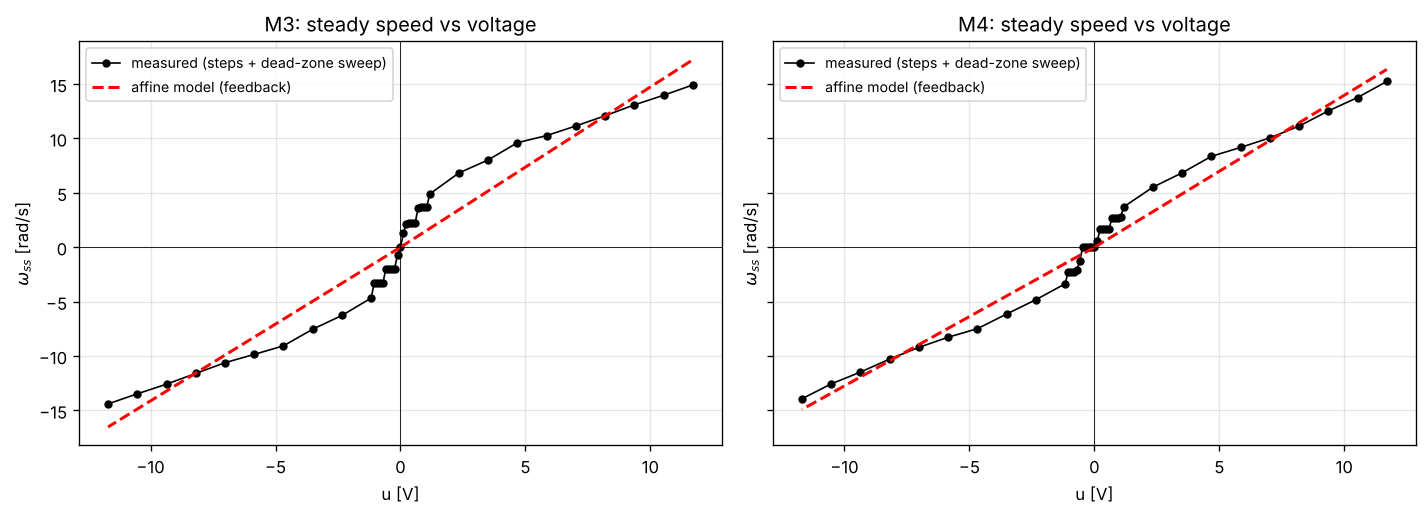

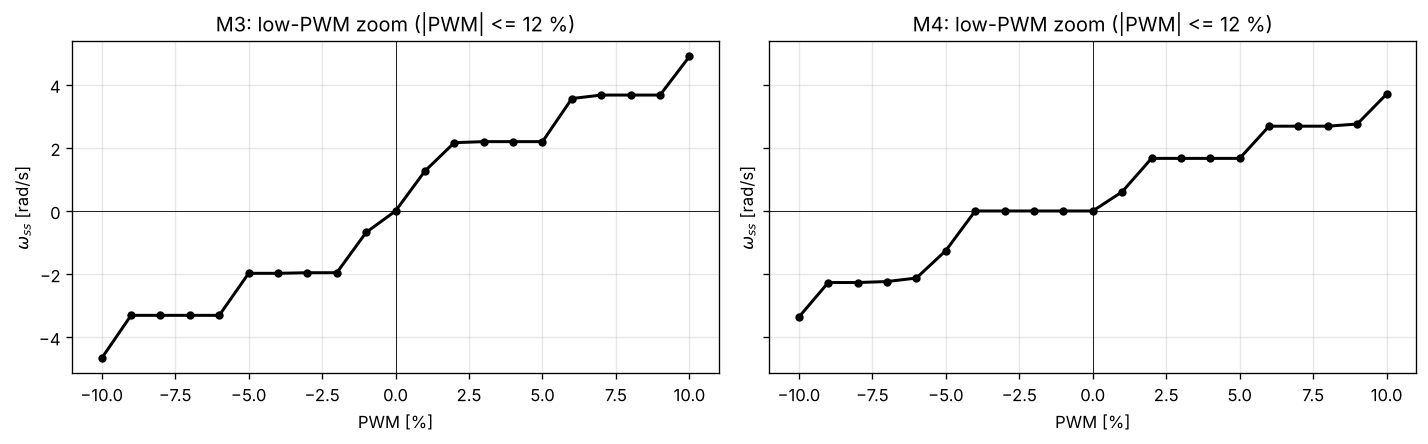

In [4]:
def stage1_affine(df, w_min=1.0, pwm_T_min=30):
    out = {}
    for name, sign in [('fw', 1), ('bw', -1)]:
        d = df[(np.sign(df.PWM) == sign) & (df.omega_ss.abs() > w_min)]
        a, c = np.polyfit(d.u, d.omega_ss, 1)
        U = -sign * c / a
        if U < 0 or a <= 0:                                  # friction cannot be negative: line through the origin
            a = float(np.sum(d.u * d.omega_ss) / np.sum(d.u ** 2)); c = 0.0; U = 0.0
        out['k_' + name] = 1.0 / a
        out['U_' + name] = U
        out['rmse_line_' + name] = rmse(d.omega_ss, a * d.u + c)
        dd = d[d.PWM.abs() >= pwm_T_min]
        out['T_eff_' + name] = dd.T_eff.mean()
        out['_line_' + name] = (a, c)
    out['k_e'] = min(out['k_fw'], out['k_bw'])
    for name in ['fw', 'bw']:
        out['b_' + name] = out['k_' + name] / out['k_e'] - 1.0
    out['T_m'] = 0.5 * (out['T_eff_fw'] * (1 + out['b_fw']) + out['T_eff_bw'] * (1 + out['b_bw']))
    return out

S1 = {m: stage1_affine(STEP[m]) for m in MOTORS}
S1_M4_rep = stage1_affine(STEP_M4_rep)

tab = pd.DataFrame({m: {'k_e [V*s/rad]': S1[m]['k_e'], 'U_fw [V]': S1[m]['U_fw'], 'U_bw [V]': S1[m]['U_bw'],
                        'b_fw (prelim.)': S1[m]['b_fw'], 'b_bw (prelim.)': S1[m]['b_bw'], 'T_m (prelim.) [s]': S1[m]['T_m'],
                        'line RMSE fw [rad/s]': S1[m]['rmse_line_fw'], 'line RMSE bw [rad/s]': S1[m]['rmse_line_bw'],
                        'speed @ +100% [rad/s]': float(MAP[m][1][1][-1]), 'speed @ -100% [rad/s]': -float(MAP[m][-1][1][-1])} for m in MOTORS})
tab['M4 repeat'] = pd.Series({'k_e [V*s/rad]': S1_M4_rep['k_e'], 'U_fw [V]': S1_M4_rep['U_fw'], 'U_bw [V]': S1_M4_rep['U_bw'],
                              'b_fw (prelim.)': S1_M4_rep['b_fw'], 'b_bw (prelim.)': S1_M4_rep['b_bw'], 'T_m (prelim.) [s]': S1_M4_rep['T_m'],
                              'line RMSE fw [rad/s]': S1_M4_rep['rmse_line_fw'], 'line RMSE bw [rad/s]': S1_M4_rep['rmse_line_bw']})
print('Stage 1, affine model fitted to the steady speeds:')
print(tab.round(3).to_string())

fig, axes = plt.subplots(1, 2, figsize=(12, 4.4), sharey=True)
for ax, m in zip(axes, MOTORS):
    ux, uy = static_curve(MAP[m])
    ax.plot(ux, uy, 'ko-', ms=4, lw=1, label='measured (steps + dead-zone sweep)')
    for name, sign in [('fw', 1), ('bw', -1)]:
        a, c = S1[m]['_line_' + name]
        uu = np.linspace(0, sign * U_battery, 50)
        ax.plot(uu, a * uu + c, 'r--', label='affine model (feedback)' if sign == 1 else None)
    ax.axhline(0, color='k', lw=0.5); ax.axvline(0, color='k', lw=0.5)
    ax.set(title=f'{m}: steady speed vs voltage', xlabel='u [V]', ylabel=r'$\omega_{ss}$ [rad/s]'); ax.legend(fontsize=8.5)
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
for ax, m in zip(axes, MOTORS):
    ux, uy = static_curve(MAP[m]); sel = np.abs(ux) <= 0.12 * U_battery
    ax.plot(ux[sel] / U_battery * 100, uy[sel], 'ko-', ms=4)
    ax.axhline(0, color='k', lw=0.5); ax.axvline(0, color='k', lw=0.5)
    ax.set(title=f'{m}: low-PWM zoom (|PWM| <= 12 %)', xlabel='PWM [%]', ylabel=r'$\omega_{ss}$ [rad/s]')
plt.tight_layout(); plt.show()

**What this shows.** The measured curve is not a line with a dead zone. At low PWM the speed rises in *steps* (the wheel runs at roughly the same speed for several neighbouring PWM levels, then jumps), and over the whole range the curve is concave: the speed at 10 % PWM is already about a third of the speed at 100 %. A straight line through such a curve has a large positive offset at $u=0$, which the model can only express as a *negative* dry friction. Since friction cannot be negative, the physical fit sets $U=0$ and the line then lies below the measured curve at low and medium PWM (a lot for M3, less for M4) and above it near 100 %.

So we compare **three models**:

* **simple:** $T_m\dot\omega+\omega=u/k_e$, both parameters fitted on the identification signal (no friction, no dead zone);
* **feedback (affine) model:** $k_e,U$ from stage 1, $T_m,b_{fw},b_{bw}$ fitted on the complex signal;
* **static-map model:** $T\,\dot\omega=g(u)-\omega$, where $g(u)$ is the *measured* curve above (stage 1, no fitting) and only the lags $T_{fw},T_{bw}$ (for forward / backward target speed) are fitted on the complex signal. The dead zone, the asymmetry and the staircase are all contained in $g$.

### 1.4 Dry friction from the dead-zone sweep
The sweep measures the **breakaway** level (lowest PWM that moves the wheel) directly, with 1 % PWM resolution.

In [5]:
MOVE_DEG = 2.0    # a level counts as "moving" if the wheel turns by more than this [deg]
DZ = {}
for m in MOTORS:
    d = DZRAW[m]
    fwd = d[(d.PWM > 0) & (d.deg.abs() > MOVE_DEG)].PWM
    bwd = d[(d.PWM < 0) & (d.deg.abs() > MOVE_DEG)].PWM
    DZ[m] = dict(fw=float(fwd.min()) if len(fwd) else np.nan, bw=float(-bwd.max()) if len(bwd) else np.nan, table=d)

def friction_voltage(m, d):
    # midpoint between the highest stuck level and the lowest moving level (+-0.5 % PWM uncertainty)
    first_move = DZ[m][d]
    stuck_level = first_move - 1
    tbl = DZ[m]['table']; sgn = 1 if d == 'fw' else -1
    has_stuck = ((tbl.PWM == sgn * stuck_level) & (tbl.deg.abs() <= MOVE_DEG)).any()
    lo = stuck_level if has_stuck else 0.0
    return 0.5 * (first_move + lo) / 100.0 * U_battery

UC = {m: dict(fw=friction_voltage(m, 'fw'), bw=friction_voltage(m, 'bw')) for m in MOTORS}
print(pd.DataFrame({m: {'breakaway fw [% PWM]': DZ[m]['fw'], 'breakaway bw [% PWM]': DZ[m]['bw'],
                        'U_c fw [V]': UC[m]['fw'], 'U_c bw [V]': UC[m]['bw']} for m in MOTORS}).round(3).to_string())
print(f'\nU_c = midpoint between the highest stuck level and the lowest moving level, uncertainty +-0.5 % PWM = +-{0.005 * U_battery:.2f} V.')

                         M3     M4
breakaway fw [% PWM]  1.000  1.000
breakaway bw [% PWM]  1.000  5.000
U_c fw [V]            0.058  0.058
U_c bw [V]            0.058  0.526

U_c = midpoint between the highest stuck level and the lowest moving level, uncertainty +-0.5 % PWM = +-0.06 V.


### 1.5 Stage 2: lag (and viscous friction) on a complex signal
Both candidate models are fitted on **one** complex signal and tested on the **other**, then the roles are swapped. The simple model is fitted on the same signal for a fair comparison.

In [6]:
RUN = {}
for m in MOTORS:
    for sig in ['chirp', 'square']:
        t, th, w, pwm, u = load_data(get_file(f'{sig}_{m}'))
        RUN[(m, sig)] = dict(t=t, theta=th, omega=w, pwm=pwm, u=u)

def simulate_map(t_log, u_log, gx, gy, T_fw, T_bw=None):
    T_bw = T_fw if T_bw is None else T_bw
    speed, angle = 0.0, 0.0
    th = np.zeros(len(t_log)); om = np.zeros(len(t_log))
    target = np.interp(u_log, gx, gy)
    for k in range(len(t_log) - 1):
        span = t_log[k + 1] - t_log[k]
        n = max(1, int(math.ceil(span / DT - 1e-9))); h = span / n
        for _ in range(n):
            speed += h * (target[k] - speed) / (T_fw if target[k] >= 0 else T_bw)
            angle += h * speed
        th[k + 1], om[k + 1] = angle, speed
    return th, om

def fit_simple(r):
    best = None
    for x0 in ([0.15, 0.6], [0.3, 0.4], [0.08, 0.9]):
        sol = least_squares(lambda x: simulate(r['t'], r['u'], simple_params(*x))[0] - r['theta'],
                            x0, bounds=([0.01, 0.1], [2.0, 5.0]), diff_step=1e-3, x_scale=[0.1, 0.3])
        if best is None or sol.cost < best.cost:
            best = sol
    return simple_params(*best.x)

def fit_affine(r, s1):
    def pk(x): return (x[0], s1['k_e'], s1['U_fw'], s1['U_bw'], x[1], x[2])
    best = None
    for x0 in ([s1['T_m'], s1['b_fw'], s1['b_bw']], [0.15, 0.1, 0.1], [0.3, 0.5, 0.5]):
        sol = least_squares(lambda x: simulate(r['t'], r['u'], pk(x))[0] - r['theta'],
                            x0, bounds=([0.01, 0, 0], [2.0, 3.0, 3.0]), diff_step=1e-3, x_scale=[0.1, 0.1, 0.1])
        if best is None or sol.cost < best.cost:
            best = sol
    return pk(best.x)

def fit_map(r, gx, gy):
    # lag for forward / backward target speed. The angle error is not convex in T, so start from a grid scan
    err = lambda x: simulate_map(r['t'], r['u'], gx, gy, x[0], x[1])[0] - r['theta']
    grid = np.linspace(0.03, 0.8, 30)
    T0 = grid[int(np.argmin([np.sum(err([T, T]) ** 2) for T in grid]))]
    best = None
    for x0 in ([T0, T0], [0.1, 0.1], [0.3, 0.3]):
        sol = least_squares(err, x0, bounds=([0.01, 0.01], [1.0, 1.0]), diff_step=1e-3, x_scale=[0.1, 0.1])
        if best is None or sol.cost < best.cost:
            best = sol
    return (float(best.x[0]), float(best.x[1]))

GX = {m: static_curve(MAP[m]) for m in MOTORS}
P_PRELIM = {m: (S1[m]['T_m'], S1[m]['k_e'], S1[m]['U_fw'], S1[m]['U_bw'], S1[m]['b_fw'], S1[m]['b_bw']) for m in MOTORS}
P_SIMPLE, P_AFF, T_MAP = {}, {}, {}
for m in MOTORS:
    for ident in ['chirp', 'square']:
        P_SIMPLE[(m, ident)] = fit_simple(RUN[(m, ident)])
        P_AFF[(m, ident)] = fit_affine(RUN[(m, ident)], S1[m])
        T_MAP[(m, ident)] = fit_map(RUN[(m, ident)], *GX[m])

NAMES = ['T_m [s]', 'k_e [V*s/rad]', 'U_fw [V]', 'U_bw [V]', 'b_fw', 'b_bw']
tab2 = pd.DataFrame({f'{m} prelim.': P_PRELIM[m] for m in MOTORS}, index=NAMES)
for m in MOTORS:
    for ident in ['chirp', 'square']:
        tab2[f'{m} affine (on {ident})'] = P_AFF[(m, ident)]
        tab2[f'{m} simple (on {ident})'] = P_SIMPLE[(m, ident)]
print(tab2.round(3).to_string())
print('\nLag (T_fw, T_bw) of the static-map model [s]:', {f'{m} on {i}': tuple(round(v, 3) for v in T_MAP[(m, i)]) for m in MOTORS for i in ['chirp', 'square']})

               M3 prelim.  M4 prelim.  M3 affine (on chirp)  M3 simple (on chirp)  M3 affine (on square)  M3 simple (on square)  M4 affine (on chirp)  M4 simple (on chirp)  M4 affine (on square)  M4 simple (on square)
T_m [s]             0.149       0.145                 0.150                 0.267                  0.137                  0.202                 0.149                 0.303                  0.144                  0.260
k_e [V*s/rad]       0.679       0.716                 0.679                 0.455                  0.679                  0.549                 0.716                 0.501                  0.716                  0.587
U_fw [V]            0.000       0.000                 0.000                 0.000                  0.000                  0.000                 0.000                 0.000                  0.000                  0.000
U_bw [V]            0.000       0.000                 0.000                 0.000                  0.000                  0.000 

### 1.6 Stage 3: RMSE of the angle for all models
*identified on* = signal used to fit the lag/viscous parameters; the static map and the stage-1 parameters never see the complex signals. If *evaluated on* = *identified on* the row is an identification error, otherwise it is a **TEST** on an unseen signal.

Motor identified on evaluated on           role  RMSE simple [rad]  RMSE affine prelim. [rad]  RMSE affine [rad]  RMSE static map [rad]
   M3         chirp        chirp identification              0.710                      1.833              0.346                  0.413
   M3         chirp       square           TEST              0.846                      0.416              3.825                  0.955
   M3        square        chirp           TEST              1.261                      1.833              1.819                  0.848
   M3        square       square identification              0.374                      0.416              0.400                  0.326
   M4         chirp        chirp identification              0.360                      1.156              0.378                  0.202
   M4         chirp       square           TEST              0.802                      0.544              3.192                  0.364
   M4        square        chirp           TEST 

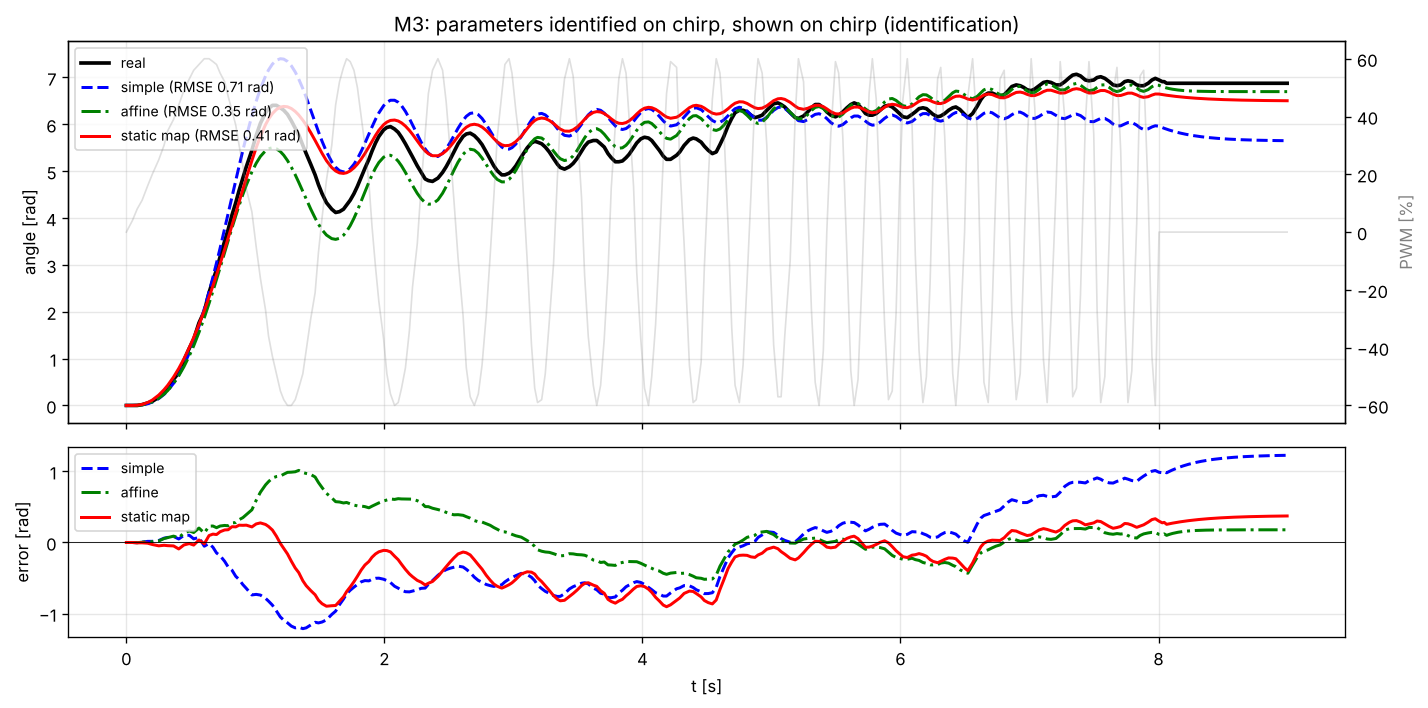

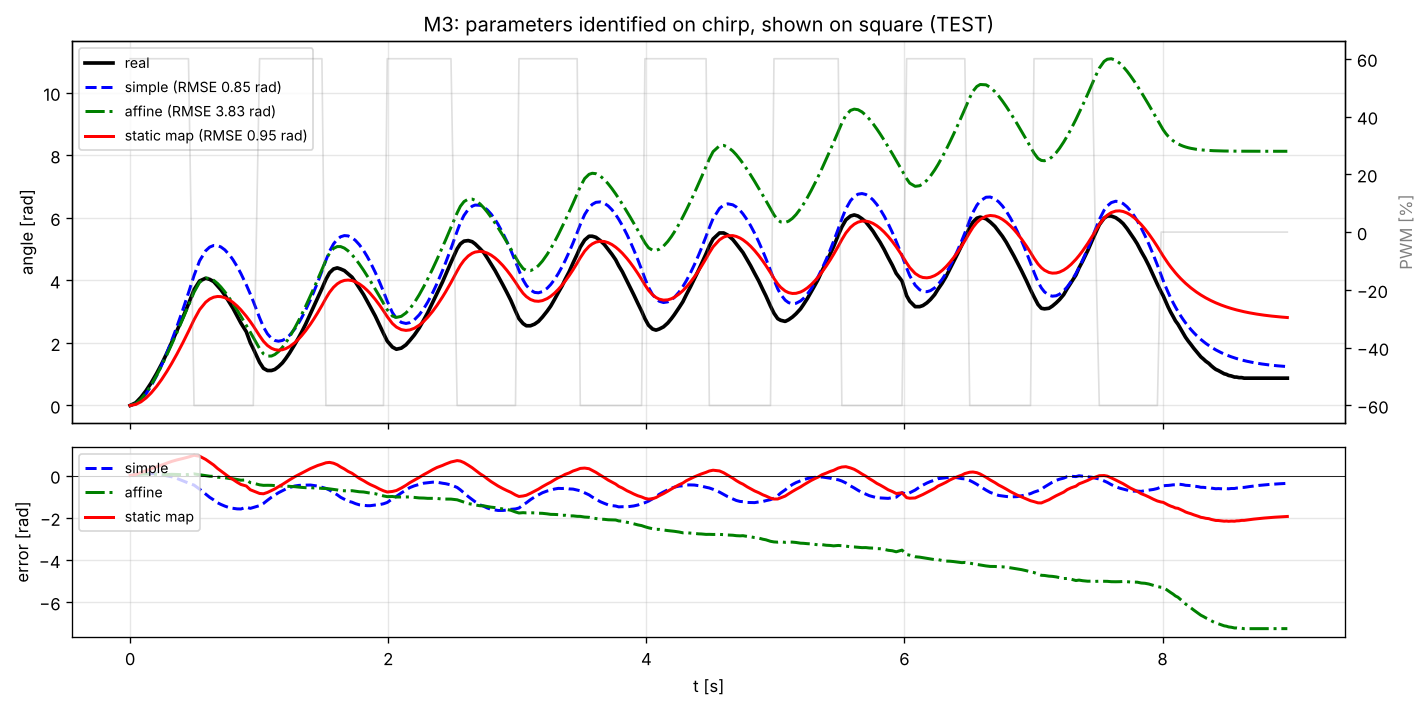

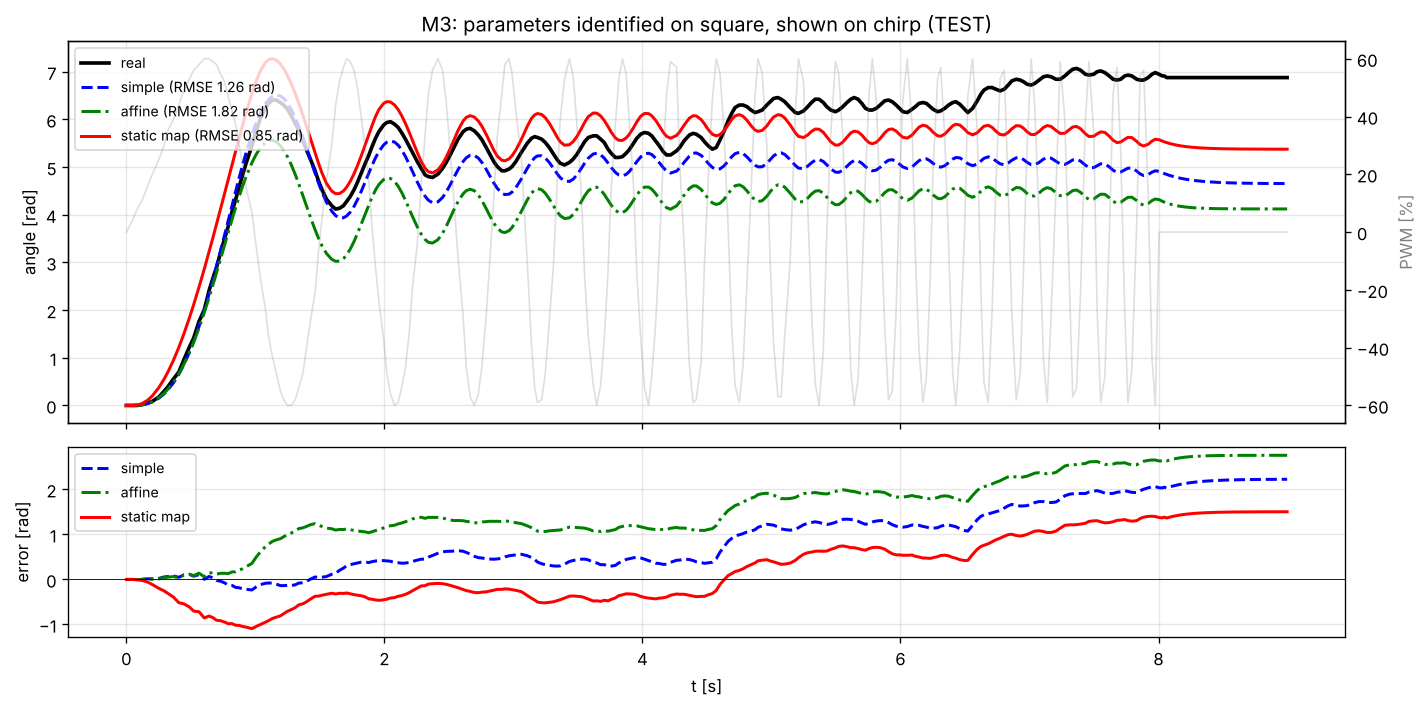

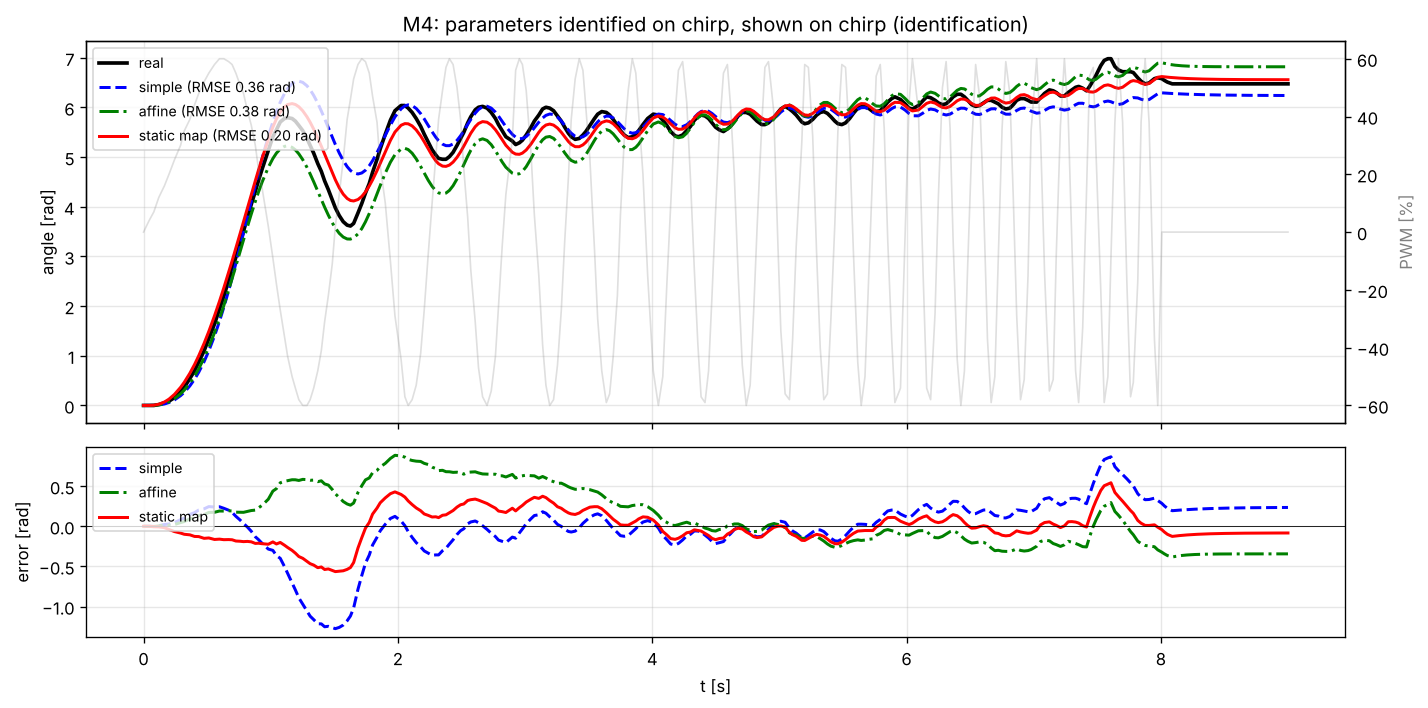

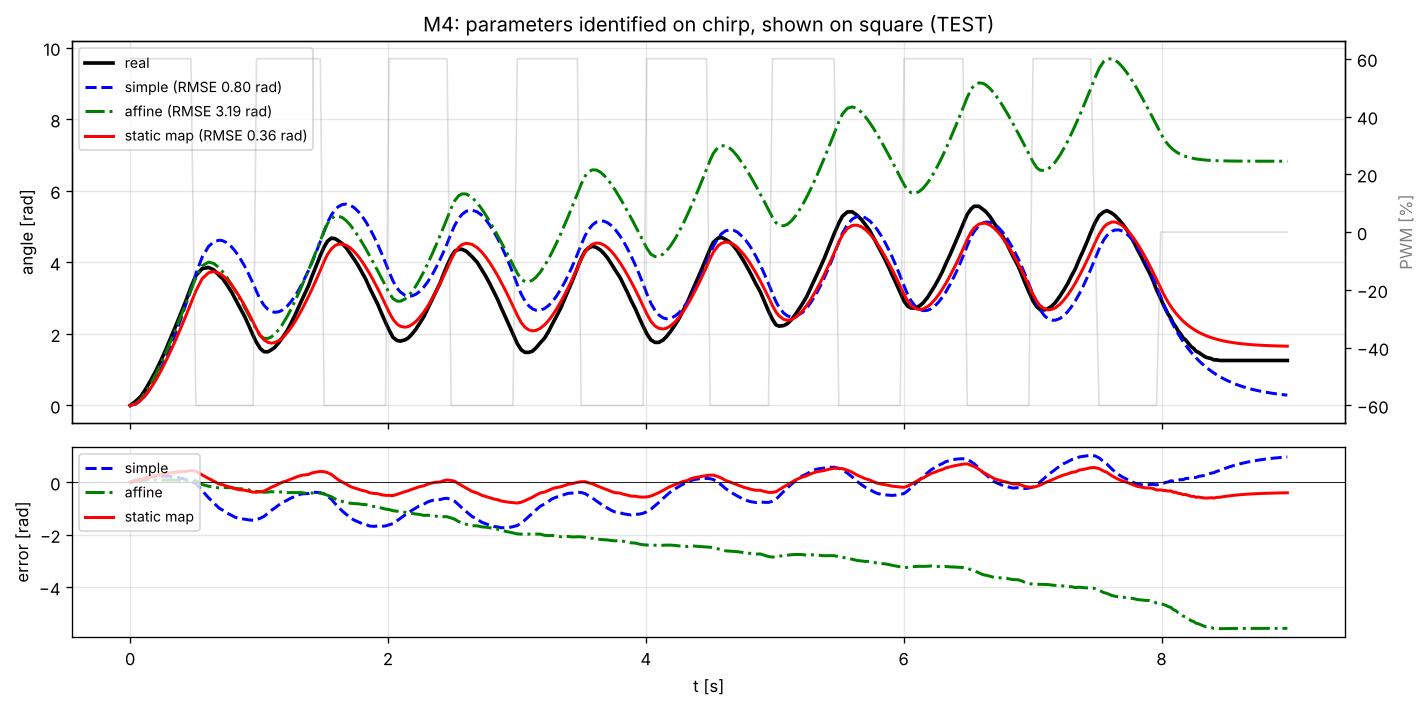

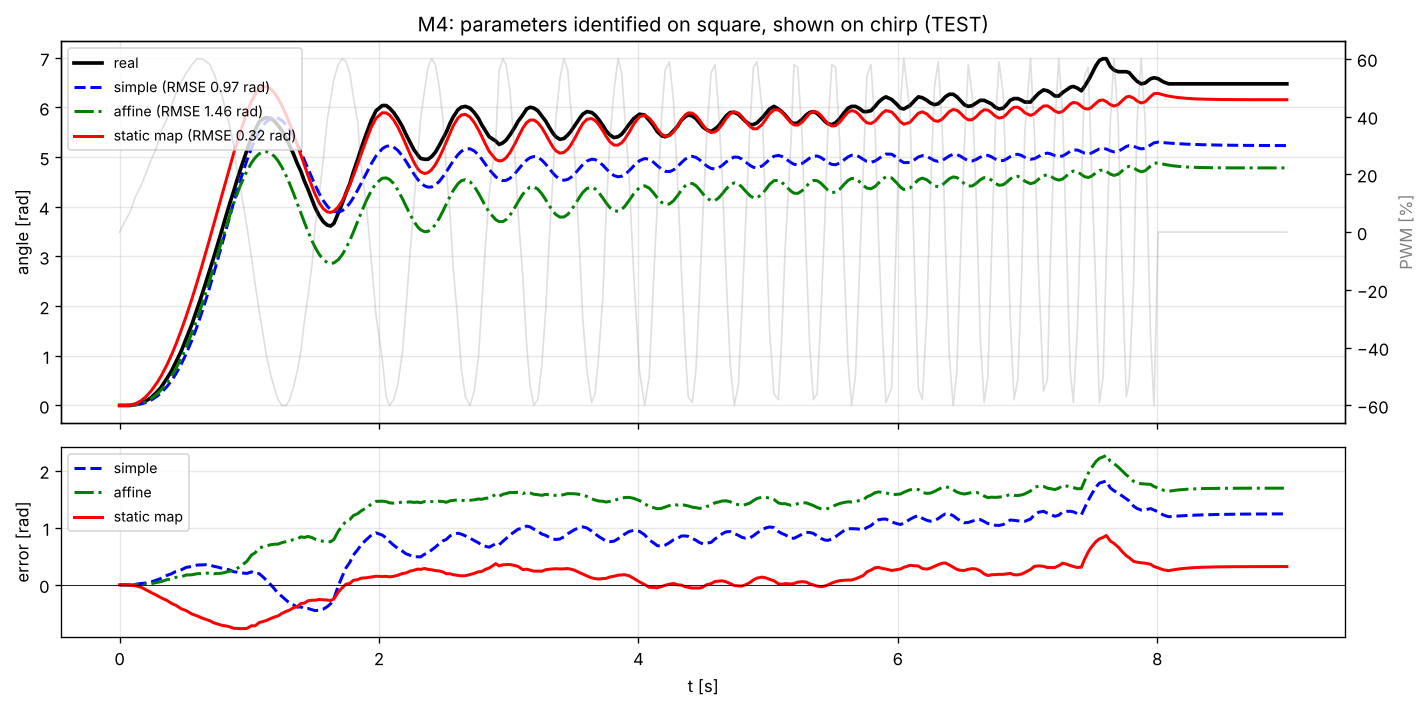

In [7]:
def predict(m, ident, model, r):
    if model == 'simple':      return simulate(r['t'], r['u'], P_SIMPLE[(m, ident)])[0]
    if model == 'affine prelim.': return simulate(r['t'], r['u'], P_PRELIM[m])[0]
    if model == 'affine':      return simulate(r['t'], r['u'], P_AFF[(m, ident)])[0]
    if model == 'static map':  return simulate_map(r['t'], r['u'], *GX[m], *T_MAP[(m, ident)])[0]
MODELS = ['simple', 'affine prelim.', 'affine', 'static map']

rows = []
for m in MOTORS:
    for ident in ['chirp', 'square']:
        for ev in ['chirp', 'square']:
            r = RUN[(m, ev)]
            row = {'Motor': m, 'identified on': ident, 'evaluated on': ev, 'role': 'identification' if ident == ev else 'TEST'}
            for name in MODELS:
                row[f'RMSE {name} [rad]'] = rmse(r['theta'], predict(m, ident, name, r))
            rows.append(row)
RESULTS = pd.DataFrame(rows)
print(RESULTS.round(3).to_string(index=False))

def plot_compare(m, ident, ev):
    r = RUN[(m, ev)]
    curves = [('simple', 'b--'), ('affine', 'g-.'), ('static map', 'r-')]
    fig, ax = plt.subplots(2, 1, figsize=(12, 6), sharex=True, gridspec_kw={'height_ratios': [2, 1]})
    ax[0].plot(r['t'], r['theta'], 'k', lw=2.2, label='real')
    for name, st in curves:
        th = predict(m, ident, name, r)
        ax[0].plot(r['t'], th, st, label=f"{name} (RMSE {rmse(r['theta'], th):.2f} rad)")
        ax[1].plot(r['t'], r['theta'] - th, st, label=name)
    ax[0].set(ylabel='angle [rad]', title=f"{m}: parameters identified on {ident}, shown on {ev} ({'identification' if ident == ev else 'TEST'})")
    ax[0].legend(loc='upper left', fontsize=8.5)
    a2 = ax[0].twinx(); a2.plot(r['t'], r['pwm'], color='grey', alpha=0.25, lw=1); a2.set_ylabel('PWM [%]', color='grey'); a2.grid(False)
    ax[1].axhline(0, color='k', lw=0.5); ax[1].set(xlabel='t [s]', ylabel='error [rad]'); ax[1].legend(loc='upper left', fontsize=8.5)
    plt.tight_layout(); plt.show()

for m in MOTORS:
    plot_compare(m, 'chirp', 'chirp')
    plot_compare(m, 'chirp', 'square')
    plot_compare(m, 'square', 'chirp')

### 1.7 Parameter set used in the rest of the report
The static map of each motor and the lags identified on the chirp (change `IDENT` to use the square wave).

In [8]:
IDENT = 'chirp'
TM = {m: T_MAP[(m, IDENT)] for m in MOTORS}
print('lag (T_fw, T_bw) of the static-map model [s]:', {m: tuple(round(v, 3) for v in TM[m]) for m in MOTORS})

lag (T_fw, T_bw) of the static-map model [s]: {'M3': (0.317, 0.315), 'M4': (0.212, 0.197)}


---
## 2. Dead-zone compensation function

In the sweep, small commands do not move the wheel (clearest for M4 backward). The compensation uses `min()` and `max()`:

* `pwm == 0` → `0`, so the robot can still stop;
* `pwm > 0` → `max(pwm, dz_fwd)`, small positive commands are lifted to the threshold (`min(100, ...)` keeps the result legal);
* `pwm < 0` → `min(pwm, -dz_bwd)`, small negative commands are lifted to `-dz_bwd` (`max(-100, ...)`).

The thresholds are the lowest moving levels measured in the dead-zone sweep (previous section), not typed in by hand.

Dead-zone thresholds [% PWM]: {'M3': {'fw': 1.0, 'bw': 1.0}, 'M4': {'fw': 1.0, 'bw': 5.0}}

M4 dead-zone sweep around zero:
  PWM  -6% ->  -192.0 deg (moving)
  PWM  -5% ->  -123.0 deg (moving)
  PWM  -4% ->    -1.0 deg (stuck)
  PWM  -3% ->    +0.0 deg (stuck)
  PWM  -2% ->    -1.0 deg (stuck)
  PWM  -1% ->    -1.0 deg (stuck)
  PWM  +1% ->   +54.0 deg (moving)
  PWM  +2% ->  +158.0 deg (moving)
  PWM  +3% ->  +161.0 deg (moving)
  PWM  +4% ->  +155.0 deg (moving)

Examples (M4):
  input -30% -> sent  -30.0%
  input  -3% -> sent   -5.0%
  input  -1% -> sent   -5.0%
  input  +0% -> sent   +0.0%
  input  +1% -> sent   +1.0%
  input  +3% -> sent   +3.0%
  input +30% -> sent  +30.0%


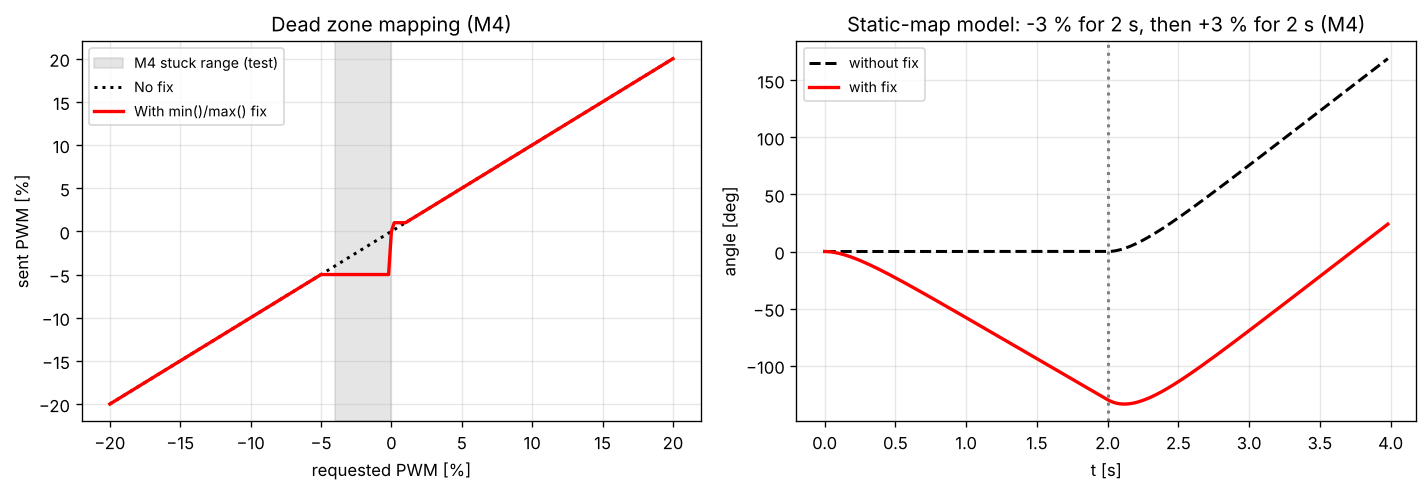

In [9]:
def fix_deadzone(pwm, dz_fwd, dz_bwd):
    if pwm > 0:
        return min(100.0, max(pwm, dz_fwd))
    elif pwm < 0:
        return max(-100.0, min(pwm, -dz_bwd))
    return 0.0

DZT = {m: dict(fw=0.0 if np.isnan(DZ[m]['fw']) else DZ[m]['fw'], bw=0.0 if np.isnan(DZ[m]['bw']) else DZ[m]['bw']) for m in MOTORS}
print('Dead-zone thresholds [% PWM]:', DZT)
d4 = DZRAW['M4']
print('\nM4 dead-zone sweep around zero:')
for _, row in d4[(d4.PWM >= -6) & (d4.PWM <= 4)].iterrows():
    print(f"  PWM {int(row.PWM):+3d}% -> {row.deg:+7.1f} deg {'(stuck)' if abs(row.deg) <= MOVE_DEG else '(moving)'}")
print('\nExamples (M4):')
for cmd in [-30, -3, -1, 0, 1, 3, 30]:
    print(f"  input {cmd:+3d}% -> sent {fix_deadzone(cmd, DZT['M4']['fw'], DZT['M4']['bw']):+6.1f}%")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.2))
cmds = np.linspace(-20, 20, 201)
ax1.axvspan(-DZT['M4']['bw'] + 1, DZT['M4']['fw'] - 1 if DZT['M4']['fw'] > 1 else 0.0, color='gray', alpha=0.2, label='M4 stuck range (test)')
ax1.plot(cmds, cmds, 'k:', label='No fix')
ax1.plot(cmds, [fix_deadzone(c, DZT['M4']['fw'], DZT['M4']['bw']) for c in cmds], 'r-', lw=2.0, label='With min()/max() fix')
ax1.set(title='Dead zone mapping (M4)', xlabel='requested PWM [%]', ylabel='sent PWM [%]'); ax1.legend(fontsize=8.5)

t_test = np.arange(0, 4.0, 0.02)
pwm_cmd = np.where(t_test < 2.0, -3.0, 3.0)
u_raw = pwm_cmd / 100 * U_battery
u_fix = np.array([fix_deadzone(c, DZT['M4']['fw'], DZT['M4']['bw']) for c in pwm_cmd]) / 100 * U_battery
th_raw, _ = simulate_map(t_test, u_raw, *GX['M4'], *TM['M4'])
th_fix, _ = simulate_map(t_test, u_fix, *GX['M4'], *TM['M4'])
ax2.plot(t_test, np.rad2deg(th_raw), 'k--', label='without fix')
ax2.plot(t_test, np.rad2deg(th_fix), 'r-', lw=2.0, label='with fix')
ax2.axvline(2.0, color='gray', ls=':')
ax2.set(title='Static-map model: -3 % for 2 s, then +3 % for 2 s (M4)', xlabel='t [s]', ylabel='angle [deg]'); ax2.legend(fontsize=8.5)
plt.tight_layout(); plt.show()

---
## 3. Coulomb friction and its cancellation

With dry friction the motor equation is

$$T_m\dot\omega + (1+b)\,\omega = \frac{u - U_c\,\mathrm{sign}(\omega)}{k_e},$$

so the friction acts as a voltage $U_c$ that is lost whenever the wheel turns. Adding it back in the direction of the wanted motion cancels it:

$$u_{sent}=u_{des}+U_c\,\mathrm{sign}(u_{des}) \;\Rightarrow\; T_m\dot\omega+(1+b)\omega=\frac{u_{des}}{k_e}.$$

$U_c$ is the breakaway voltage from the dead-zone sweep (midpoint between the highest stuck level and the lowest moving level, so $\pm0.5\,\%$ PWM). It is the only dry-friction estimate that the data support: the affine model of the step series cannot produce a positive $U$ (previous section).

**What the data say about the result.** The check uses the *measured* static curves. Because the real curves are staircase-shaped and concave, adding $U_c$ removes the dead band and the start-up offset but cannot make the speed proportional to $u_{des}$; Section 4 addresses that.

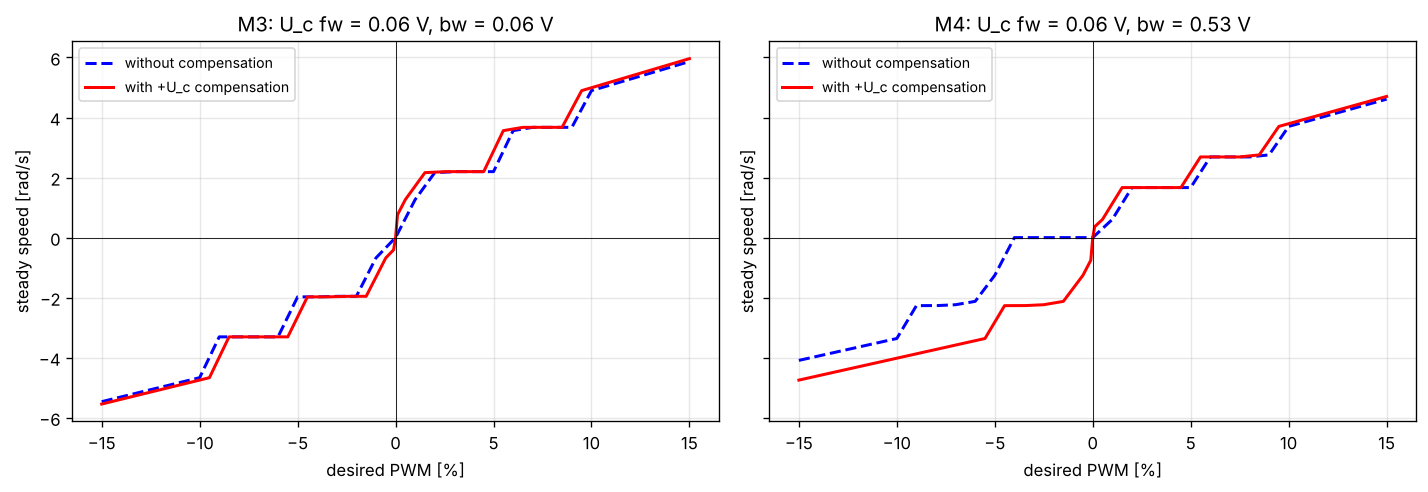

Steady speed [rad/s] for small commands, without -> with compensation:
  M3  -5% :  -1.97 ->  -2.64
  M3  -3% :  -1.96 ->  -1.97
  M3  -1% :  -0.68 ->  -1.32
  M3  +1% :  +1.27 ->  +1.72
  M3  +3% :  +2.20 ->  +2.20
  M3  +5% :  +2.20 ->  +2.88
  M4  -5% :  -1.26 ->  -2.81
  M4  -3% :  -0.00 ->  -2.25
  M4  -1% :  -0.00 ->  -1.69
  M4  +1% :  +0.61 ->  +1.14
  M4  +3% :  +1.67 ->  +1.67
  M4  +5% :  +1.67 ->  +2.18


In [10]:
def cancel_friction(u_des, U_fw, U_bw, U_max):
    if u_des > 0:
        return min(U_max, u_des + U_fw)
    elif u_des < 0:
        return max(-U_max, u_des - U_bw)
    return 0.0

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), sharey=True)
for ax, m in zip(axes, MOTORS):
    pw = np.linspace(-15, 15, 301); ud = pw / 100 * U_battery
    uc = np.array([cancel_friction(x, UC[m]['fw'], UC[m]['bw'], U_battery) for x in ud])
    ax.plot(pw, np.interp(ud, *GX[m]), 'b--', label='without compensation')
    ax.plot(pw, np.interp(uc, *GX[m]), 'r-', label='with +U_c compensation')
    ax.axhline(0, color='k', lw=0.5); ax.axvline(0, color='k', lw=0.5)
    ax.set(title=f"{m}: U_c fw = {UC[m]['fw']:.2f} V, bw = {UC[m]['bw']:.2f} V", xlabel='desired PWM [%]', ylabel=r'steady speed [rad/s]'); ax.legend(fontsize=8.5)
plt.tight_layout(); plt.show()

print('Steady speed [rad/s] for small commands, without -> with compensation:')
for m in MOTORS:
    for p in [-5, -3, -1, 1, 3, 5]:
        ud = p / 100 * U_battery; uc = cancel_friction(ud, UC[m]['fw'], UC[m]['bw'], U_battery)
        print(f"  {m} {p:+3d}% : {np.interp(ud, *GX[m]):+6.2f} -> {np.interp(uc, *GX[m]):+6.2f}")

---
## 4. Backward–forward asymmetry compensation

From the measured curves, forward and backward speed differ at the same $|u|$ (different gain, and on M4 a different dead band). We want $+u_{des}$ and $-u_{des}$ to give the **same speed magnitude**. Instead of boosting the weaker side (it would reach $100\%$ early), the stronger side is brought down to it:

1. reference curve $g_{ref}(x)=\min\big(g_{fw}(x),\,|g_{bw}(-x)|\big)$ for $x=|u_{des}|$;
2. command $u_{cmd}=g_{dir}^{-1}\big(g_{ref}(x)\big)$ in each direction, using the measured curves.

This removes both the gain asymmetry and the asymmetric start-up offset in one step, and it reduces to the earlier idea (scale by the ratio of the constants, add the friction voltage) if the curves were straight lines. It does not remove differences in the lag, and a request below the weaker side's dead band still gives no motion (use the Section 2 function for that).

To tie the check to the real experiment, the real square-wave PWM is replayed through the static-map model before and after the compensation and compared with the measured angle.

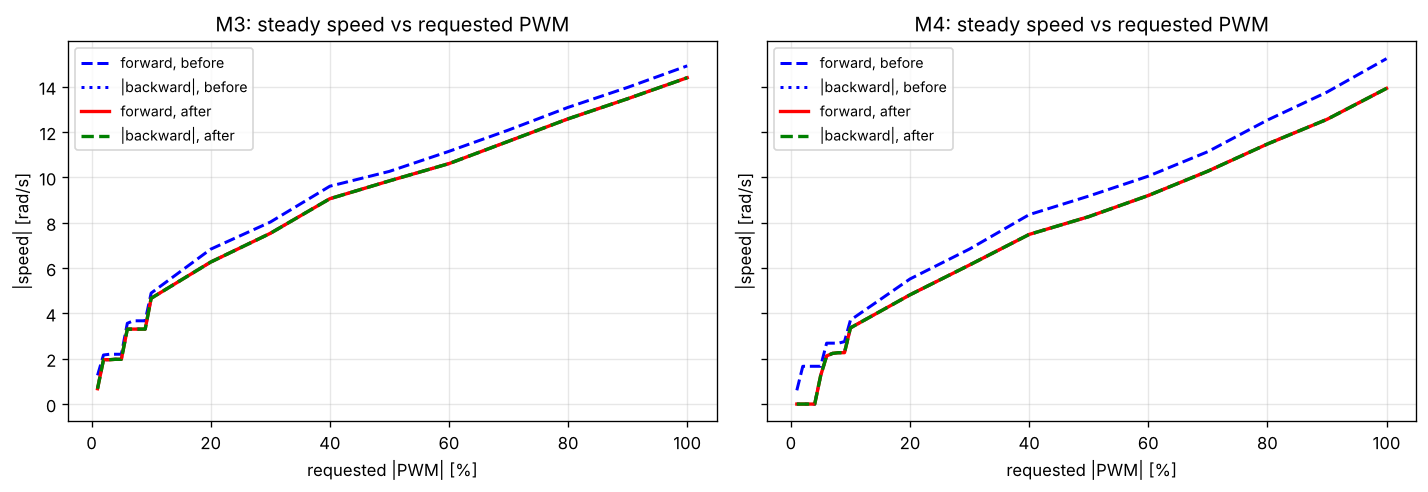

Examples (M4): requested -> sent
  -60% -> -60.00%
  -30% -> -30.00%
  -10% -> -10.00%
  +10% ->  +9.64%
  +30% -> +24.67%
  +60% -> +50.28%
M3: square wave final angle: measured = +50.0 deg | model, no comp. = +161.1 deg | model, compensated = +37.1 deg
M4: square wave final angle: measured = +72.0 deg | model, no comp. = +94.9 deg | model, compensated = -95.4 deg


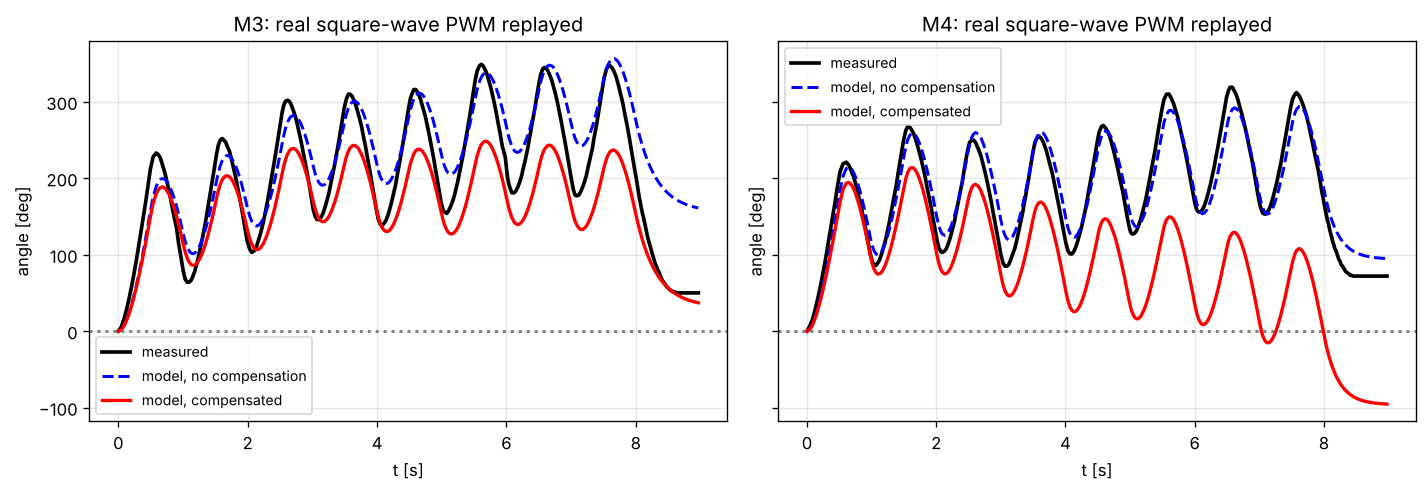

In [11]:
def make_compensator(side_tables):
    ux_f, uy_f = side_tables[1]; ux_b, uy_b = side_tables[-1]
    eps = 1e-6                                           # makes the plateaus strictly increasing for the inversion
    def g_ref(x): return np.minimum(np.interp(x, ux_f, uy_f), np.interp(x, ux_b, uy_b))
    def comp(pwm_des, U_batt=None):
        U_batt = U_battery if U_batt is None else U_batt
        if pwm_des == 0:
            return 0.0
        x = abs(pwm_des) / 100.0 * U_batt
        target = g_ref(x)
        ux, uy = (ux_f, uy_f) if pwm_des > 0 else (ux_b, uy_b)
        u_cmd = float(np.interp(target, uy + eps * ux, ux))
        return float(np.sign(pwm_des) * min(100.0, u_cmd / U_batt * 100.0))
    return comp

COMP = {m: make_compensator(MAP[m]) for m in MOTORS}

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), sharey=True)
for ax, m in zip(axes, MOTORS):
    pw = np.linspace(1, 100, 100); ud = pw / 100 * U_battery
    f0 = np.interp(ud, *MAP[m][1]); b0 = np.interp(ud, *MAP[m][-1])
    f1 = np.interp(np.array([COMP[m](p) for p in pw]) / 100 * U_battery, *MAP[m][1])
    b1 = np.interp(np.array([-COMP[m](-p) for p in pw]) / 100 * U_battery, *MAP[m][-1])
    ax.plot(pw, f0, 'b--', label='forward, before'); ax.plot(pw, b0, 'b:', label='|backward|, before')
    ax.plot(pw, f1, 'r-', lw=2, label='forward, after'); ax.plot(pw, b1, 'g--', lw=2, label='|backward|, after')
    ax.set(title=f'{m}: steady speed vs requested PWM', xlabel='requested |PWM| [%]', ylabel='|speed| [rad/s]'); ax.legend(fontsize=8.5)
plt.tight_layout(); plt.show()

print('Examples (M4): requested -> sent')
for p in [-60, -30, -10, 10, 30, 60]:
    print(f'  {p:+3d}% -> {COMP["M4"](p):+6.2f}%')

def replay(m, t, pwm, comp):
    pc = np.array([COMP[m](x) if comp else x for x in pwm])
    return simulate_map(t, pc / 100 * U_battery, *GX[m], *TM[m])[0]

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), sharey=True)
for ax, m in zip(axes, MOTORS):
    rs = RUN[(m, 'square')]
    th_raw, th_fix = replay(m, rs['t'], rs['pwm'], False), replay(m, rs['t'], rs['pwm'], True)
    ax.plot(rs['t'], np.rad2deg(rs['theta']), 'k', lw=2.2, label='measured'); ax.plot(rs['t'], np.rad2deg(th_raw), 'b--', label='model, no compensation')
    ax.plot(rs['t'], np.rad2deg(th_fix), 'r-', lw=2, label='model, compensated'); ax.axhline(0, color='gray', ls=':')
    ax.set(title=f'{m}: real square-wave PWM replayed', xlabel='t [s]', ylabel='angle [deg]'); ax.legend(fontsize=8.5)
    print(f"{m}: square wave final angle: measured = {np.rad2deg(rs['theta'][-1]):+.1f} deg | model, no comp. = {np.rad2deg(th_raw[-1]):+.1f} deg | model, compensated = {np.rad2deg(th_fix[-1]):+.1f} deg")
plt.tight_layout(); plt.show()

**Reading the replay.** The uncompensated model reproduces the measured square-wave angle well, so the replay is a meaningful check. The compensation makes the *steady-state* speeds equal in both directions, but a 1 Hz square wave has half-periods of only 0.5 s, comparable to the lag $T\approx0.2$ s, so the wheel never reaches steady speed. The steady-state gain difference therefore turns into a smaller travel difference per cycle, and a compensation designed from steady-state curves can **over-correct** fast reversals (compare the final angles printed above for M3 and M4). A compensation for fast switching has to take the lag and the reversal into account, or be tuned on the signal it is meant for. These are model predictions; the real check is to run the compensated PWM on the robot.

---
## 5. Summary

In [12]:
test = RESULTS[RESULTS['role'] == 'TEST']; ident_rows = RESULTS[RESULTS['role'] == 'identification']
cols = [f'RMSE {n} [rad]' for n in MODELS]
print('Mean angle RMSE [rad]  ' + '  '.join(f'{n:>14s}' for n in MODELS))
for name, d in [('identification', ident_rows), ('test', test)]:
    print(f'  {name:14s}       ' + '  '.join(f'{d[c].mean():14.3f}' for c in cols))
print()
print(RESULTS.loc[RESULTS['role'] == 'TEST', ['Motor', 'identified on', 'evaluated on'] + cols].round(3).to_string(index=False))

Mean angle RMSE [rad]          simple  affine prelim.          affine      static map
  identification                0.525           0.987           0.346           0.297
  test                          0.969           0.987           2.574           0.622

Motor identified on evaluated on  RMSE simple [rad]  RMSE affine prelim. [rad]  RMSE affine [rad]  RMSE static map [rad]
   M3         chirp       square              0.846                      0.416              3.825                  0.955
   M3        square        chirp              1.261                      1.833              1.819                  0.848
   M4         chirp       square              0.802                      0.544              3.192                  0.364
   M4        square        chirp              0.965                      1.156              1.461                  0.323
